# What the descriptions say, and a better way to read them

Every discharge application has a free-text `description`. This notebook:
1. Shows what a description is made of.
2. Shows why the keyword tagger from `analysis.py` mislabels topics.
3. Compares it with labels from **Jev** (`~typesafe/jev-latest` through OpenRouter's decisions API), asked typed questions about only the conditions being signed off.
4. Rechecks the page's topic and bundling findings, and the late model, using JEV's labels.

Jev labels come from `src/conditions_queue/classify_jev.py` and are stored in `outputs/jev_topics.jsonl`. This notebook doesn't call the API.

## 1 · Load

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))  # run from notebooks/: make src/ importable
from conditions_queue import paths

import json, re, textwrap, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.metrics import roc_auc_score
from conditions_queue.features import CAT, NUM, TOPIC_COLS, TOPICS, slug, load_dataset, time_split

pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 200)
jev = pd.DataFrame([json.loads(l) for l in open(paths.OUTPUTS / "jev_topics.jsonl")]).drop_duplicates("name")
d = load_dataset()                                  # model population (2021-25, not withdrawn)
d = d.merge(jev.add_prefix("jev_").rename(columns={"jev_name": "name"}), on="name", how="left")
print(f"JEV labels: {len(jev):,} descriptions · matched to {d['jev_topics'].notna().mean():.1%} of the {len(d):,} modelled applications")

JEV labels: 17,079 descriptions · matched to 100.0% of the 16,284 modelled applications


## 2 · Anatomy of a description

A typical description has two parts:

| Part | Example | What it tells us |
|---|---|---|
| **The request** | "Approval of details pursuant to conditions 35 (Air Quality and Dust Management Plan), 48 (Construction and Environmental Management Plan)…" | Which conditions are being signed off, and usually what they cover |
| **The original permission, copied in** | "…of planning permission 19/02840/FUL (Demolition of the existing buildings and erection of a part 6 and part 7 storey building to provide 51 residential flats… cycle stores, car parking spaces, refuse/recycling stores, landscaping…)" | What the scheme is: homes, storeys, uses. **Not** what is being signed off |

In [2]:
for r in d.sample(4, random_state=7).itertuples():
    print(textwrap.fill(r.description, 150)); print()
words = d["description"].str.split().str.len()
print(f"Median length {words.median():.0f} words · 90% are under {words.quantile(.9):.0f} words")
cond_no = d["description"].str.contains(r"condition[s]?\s*\(?\d", case=False).mean()
perm_ref = d["description"].str.contains(r"\d{2,4}/\d{3,6}").mean()
print(f"Mentions a condition number: {cond_no:.0%}")
print(f"Mentions the original permission's reference: {perm_ref:.0%}")

Details required for Condition 20 (Construction Management Plan) of planning permission 20/00555/FUL (Demolition of an existing single storey building
and erection of a two storey building to accommodate 4 x apartments and 4x outdoor parking spaces)

Details of condition 9 (Hard and Soft Landscaping) as required by planning permission ref. 21/AP/4729 dated 17/04/2023 for 'Demolition of existing
teaching block, caretakers house, playground canopies and dividing walls; construction of a new single storey extension and part refurbishment of the
existing main school building; construction of a new single storey classroom block and kitchen dining block; and associated soft and hard landscaping
improvement works'.

Approval of details pursuant to condition 6 (Demolition and Construction Method Statement) of planning permission 18/01093/FUL (Redevelopment of site
involving the demolition of existing buildings with part retention of annexe and the erection of a 4 storey building (plus basement

Median length 62 words · 90% are under 123 words


Mentions a condition number: 91%
Mentions the original permission's reference: 82%


## 3 · The keyword tagger's problem

The tagger in `analysis.py` searches the **whole** description for words like "cycle" or "landscaping". But those words usually come from the copied scheme text ("…with cycle storage, refuse storage and landscaping"), not from the condition being signed off.

In [3]:
has = d["jev_topics"].notna()
rows = []
for t in TOPICS:
    kw = d.loc[has, slug(t)].astype(bool)
    llm = d.loc[has, "jev_topics"].apply(lambda ts: t in ts)
    rows.append({"topic": t, "keyword tagger %": 100 * kw.mean(), "JEV %": 100 * llm.mean(),
                 "keyword tags JEV agrees with %": 100 * (kw & llm).sum() / max(kw.sum(), 1),
                 "JEV tags the keywords found %": 100 * (kw & llm).sum() / max(llm.sum(), 1)})
cmp_topics = pd.DataFrame(rows).set_index("topic").sort_values("keyword tagger %", ascending=False)
cmp_topics.round(0)

,keyword tagger %,JEV %,keyword tags JEV agrees with %,JEV tags the keywords found %
topic,,,,
"Waste, cycle & parking",77.0,18.0,23.0,98.0
Landscaping & trees,61.0,18.0,28.0,93.0
Materials & design detail,20.0,18.0,73.0,81.0
Piling & structure,20.0,4.0,14.0,62.0
Energy & carbon,18.0,12.0,56.0,82.0
Construction logistics / management,10.0,17.0,100.0,61.0
Boundary & lighting,10.0,6.0,49.0,76.0
Drainage & flood,10.0,10.0,89.0,85.0
"Noise, vibration & air",9.0,11.0,97.0,77.0


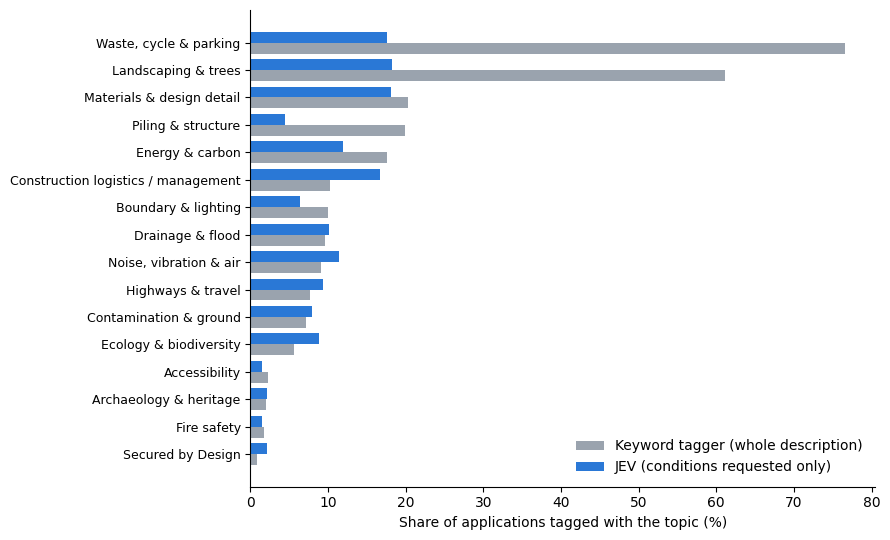

In [4]:
fig, ax = plt.subplots(figsize=(9, 5.5))
y = np.arange(len(cmp_topics))
ax.barh(y + 0.2, cmp_topics["keyword tagger %"], height=0.4, color="#9aa3ae", label="Keyword tagger (whole description)")
ax.barh(y - 0.2, cmp_topics["JEV %"], height=0.4, color="#2a78d6", label="JEV (conditions requested only)")
ax.set_yticks(y); ax.set_yticklabels(cmp_topics.index, fontsize=9); ax.invert_yaxis()
ax.set_xlabel("Share of applications tagged with the topic (%)")
ax.legend(frameon=False, loc="lower right"); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

**Reading this:** where the grey bar is much longer than the blue one, the keyword tagger is mostly tagging the **scheme**, not the condition. "Keyword tags JEV agrees with" is the share of keyword tags that JEV confirms. A low value means most of that topic's keyword tags are false alarms.

### Spot check: disagreements

Read a few cases where the two disagree to judge which is right:

In [5]:
dis = d[has].copy()
dis = dis[dis["jev_topics"].apply(len) > 0]
dis["kw"] = dis[TOPIC_COLS].apply(lambda r: sorted(t for t, c in zip(TOPICS, TOPIC_COLS) if r[c]), axis=1)
dis = dis[dis["kw"].apply(set) != dis["jev_topics"].apply(set)]
print(f"Disagree on at least one topic: {len(dis) / has.sum():.0%} of applications\n")
for r in dis.sample(6, random_state=1).itertuples():
    print(textwrap.shorten(r.description, 260))
    print(f"   keyword: {r.kw}\n   JEV:     {r.jev_topics}\n")

Disagree on at least one topic: 77% of applications

Discharge of condition number 15 (energy) attached to planning permission ref. 18/04264/FUL. (Demolition of existing buildings; Erection of 2 x three/four storey buildings comprising 8 x one bedroom, 16 x two bedroom and 4 x three bedroom flats. [...]
   keyword: ['Energy & carbon', 'Landscaping & trees', 'Waste, cycle & parking']
   JEV:     ['Energy & carbon']

Details of a Fire Safety Statement pursuant to Condition 11 of planning permission ref: 200471FUL and amended by 213715VAR dated 16/12/2020 for: 'Redevelopment of the site to provide 125 residential units accommodated within two residential buildings [...]
   keyword: ['Fire safety', 'Landscaping & trees', 'Waste, cycle & parking']
   JEV:     ['Fire safety']

Discharge of Condition 10 (electric vehicle charging points) and Condition 11 (external energy generation measures) attached to planning permission 23/02472/FUL for the 'Partial demolition and extension of existing bun

## 4 · Counting conditions

In [6]:
both = d[has & d["jev_n_conditions"].notna()]
print(f"JEV and the regex count agree on {(both['jev_n_conditions'] == both['n_cond']).mean():.0%} of applications")
print(f"Regex says 1 but JEV says more: {((both['n_cond'] == 1) & (both['jev_n_conditions'] > 1)).mean():.1%}")
print(f"Topic named in the request (JEV): {d.loc[has, 'jev_topic_stated'].mean():.0%}")
print(f"Request says the details are needed before work starts: {(d.loc[has, 'jev_pre_commencement'] == True).mean():.0%}")
pd.crosstab(both["n_cond"].clip(upper=7), both["jev_n_conditions"].clip(upper=7), margins=True,
            rownames=["regex count"], colnames=["JEV count"])

JEV and the regex count agree on 88% of applications
Regex says 1 but JEV says more: 10.3%
Topic named in the request (JEV): 98%
Request says the details are needed before work starts: 0%


JEV count,1.0,2.0,3.0,4.0,5.0,6.0,7.0,All
regex count,,,,,,,,
1,11733,906,331,172,108,68,94,13412
2,10,1210,73,18,5,2,3,1321
3,0,1,583,32,5,6,4,631
4,0,0,1,333,31,5,3,373
5,0,0,0,1,190,16,2,209
6,0,0,0,0,0,123,12,135
7,0,0,0,0,0,1,160,161
All,11743,2117,988,556,339,221,278,16242


## 5 · Do the page's findings survive?

Recalculate the page's two topic-based findings using JEV's labels. Late = decided after 8 weeks, or still undecided past 8 weeks. Refused = refused or only partly approved (decided applications only).

In [7]:
dd = d[has].copy()
dd["refused"] = dd["outcome"].isin(["refused", "partial"]).astype(float).where(dd["decided"] == 1)

def topic_table(flag):
    out = []
    for t in TOPICS:
        m = flag(t)
        if m.sum() >= 150:
            out.append({"topic": t, "applications": int(m.sum()), "late %": 100 * dd.loc[m, "late"].mean(),
                        "refused or partial %": 100 * dd.loc[m, "refused"].mean()})
    return pd.DataFrame(out).set_index("topic")

kw_tab = topic_table(lambda t: dd[slug(t)].astype(bool))
jev_tab = topic_table(lambda t: dd["jev_topics"].apply(lambda ts: t in ts))
both_tab = jev_tab.join(kw_tab, lsuffix=" (JEV)", rsuffix=" (keyword)", how="outer")
print(f"All applications: late {100 * dd['late'].mean():.0f}%, refused or partial {100 * dd['refused'].mean():.0f}%")
both_tab.sort_values("late % (JEV)", ascending=False).round(0)

All applications: late 56%, refused or partial 13%


,applications (JEV),late % (JEV),refused or partial % (JEV),applications (keyword),late % (keyword),refused or partial % (keyword)
topic,,,,,,
Piling & structure,725,66.0,12.0,3249.0,58.0,7.0
Boundary & lighting,1046,65.0,17.0,1618.0,60.0,14.0
Accessibility,243,65.0,12.0,364.0,56.0,7.0
Drainage & flood,1644,64.0,22.0,1561.0,65.0,22.0
Fire safety,249,64.0,23.0,277.0,63.0,20.0
Highways & travel,1527,64.0,16.0,1250.0,63.0,5.0
Construction logistics / management,2725,64.0,16.0,1669.0,64.0,19.0
Landscaping & trees,2963,61.0,19.0,9962.0,57.0,12.0
Materials & design detail,2950,61.0,18.0,3310.0,57.0,17.0


In [8]:
dd["n_jev"] = dd["jev_n_conditions"].fillna(dd["n_cond"])
bund = pd.DataFrame({
    "applications (JEV count)": dd.groupby(pd.cut(dd["n_jev"], [0, 1, 3, 6, 99], labels=["1", "2-3", "4-6", "7+"]))["late"].size(),
    "late % (JEV count)": dd.groupby(pd.cut(dd["n_jev"], [0, 1, 3, 6, 99], labels=["1", "2-3", "4-6", "7+"]))["late"].mean() * 100,
    "late % (regex count)": dd.groupby(pd.cut(dd["n_cond"], [0, 1, 3, 6, 99], labels=["1", "2-3", "4-6", "7+"]))["late"].mean() * 100,
    "refused % (JEV count)": dd.groupby(pd.cut(dd["n_jev"], [0, 1, 3, 6, 99], labels=["1", "2-3", "4-6", "7+"]))["refused"].mean() * 100,
})
bund.round(0)

,applications (JEV count),late % (JEV count),late % (regex count),refused % (JEV count)
1,11784,53.0,54.0,10.0
2-3,3106,61.0,64.0,18.0
4-6,1116,70.0,73.0,23.0
7+,278,81.0,86.0,28.0


## 6 · Does the late model improve with JEV features?

Swap the 16 keyword topic flags and the regex condition count for JEV's versions, keeping everything else the same. Each version is fitted with 5 random seeds on the same time split.

In [9]:
jt = pd.DataFrame({"jev_" + slug(t)[2:]: d["jev_topics"].apply(lambda ts: int(isinstance(ts, list) and t in ts)) for t in TOPICS})
d2 = pd.concat([d, jt], axis=1)
d2["jev_n_cond_c"] = d2["jev_n_conditions"].fillna(d2["n_cond"]).clip(upper=10)
d2["jev_n_topics"] = jt.sum(axis=1)
d2["jev_topic_stated"] = d2["jev_topic_stated"].fillna(False).astype(int)
d2["jev_precommencement"] = d2["jev_pre_commencement"].map({True: 1, False: 0})
JEV_COLS = list(jt.columns) + ["jev_n_cond_c", "jev_n_topics", "jev_topic_stated", "jev_precommencement"]
BASE_NO_TEXT = [c for c in NUM if c not in TOPIC_COLS + ["n_cond_c", "n_topics", "any_precommencement"]]

train, test = time_split(d2)
cat_levels = {c: train[c].astype("category").cat.categories for c in CAT}
GBM = dict(n_estimators=400, learning_rate=0.03, num_leaves=31, min_child_samples=40,
           subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1)

def prep(X, feats):
    X = X[feats].copy()
    for c in CAT:
        X[c] = pd.Categorical(X[c], categories=cat_levels[c])
    return X

rows = []
for label, num in [("No description features", BASE_NO_TEXT),
                   ("Keyword features (current)", NUM),
                   ("JEV features instead", BASE_NO_TEXT + JEV_COLS),
                   ("Both", NUM + JEV_COLS)]:
    aucs = []
    for seed in range(5):
        m = lgb.LGBMClassifier(**GBM, random_state=seed).fit(prep(train, CAT + num), train["late"])
        aucs.append(roc_auc_score(test["late"], m.predict_proba(prep(test, CAT + num))[:, 1]))
    rows.append({"features": label, "Late AUC": np.mean(aucs), "± (5 seeds)": np.std(aucs)})
pd.DataFrame(rows).set_index("features").round(3)

,Late AUC,± (5 seeds)
features,,
No description features,0.596,0.001
Keyword features (current),0.627,0.002
JEV features instead,0.636,0.001
Both,0.635,0.001


## 7 · Summary

In [10]:
print("Filled in from the results above when the notebook runs:")
top_false = cmp_topics.sort_values("keyword tags JEV agrees with %").head(3)
print("Least reliable keyword topics:", ", ".join(f"{t} ({v:.0f}% confirmed)" for t, v in top_false["keyword tags JEV agrees with %"].items()))

Filled in from the results above when the notebook runs:
Least reliable keyword topics: Piling & structure (14% confirmed), Waste, cycle & parking (23% confirmed), Landscaping & trees (28% confirmed)
